# Лабораторная работа №3. Решающее дерево

Исследуем классификацию ответа об употреблении каннабиса за последние 12 месяцев и недельный прогноз обращений о граффити. Сохраним цели, тесты и фолды из первой работы. Для каждой задачи сравним исходную и выбранную по CV библиотечные модели, затем собственные реализации в тех же условиях.

## 1. Данные и условия сравнения

Загрузим оба исходных набора по прямым ссылкам. Drug Consumption содержит 1885 анкет; используем 12 характеристик и цель `CL3–CL6` против `CL0–CL2`. В Chicago построим недельные счётчики для всех 77 районов, исключив дубликаты. Все признаки истории известны до начала прогнозируемой недели.

In [ ]:
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42
DATA_DIR = Path("datasets")
DATA_DIR.mkdir(exist_ok=True)
DRUG_PATH = DATA_DIR / "drug_consumption.data"
GRAFFITI_PATH = DATA_DIR / "Chicago_graffiti.csv"

def download(url, destination, min_bytes):
    if destination.exists() and destination.stat().st_size >= min_bytes:
        print(f"Уже есть: {destination} ({destination.stat().st_size / 1e6:.1f} МБ)")
        return
    temporary = destination.with_suffix(destination.suffix + ".part")
    with urlopen(url, timeout=120) as response, temporary.open("wb") as output:
        shutil.copyfileobj(response, output)
    if temporary.stat().st_size < min_bytes:
        temporary.unlink()
        raise RuntimeError(f"Файл {destination.name} слишком мал: возможно, скачана лишь часть данных")
    temporary.replace(destination)

if not DRUG_PATH.exists():
    archive = DATA_DIR / "drug_consumption.zip"
    download("https://archive.ics.uci.edu/static/public/373/drug+consumption+quantified.zip", archive, 100_000)
    with ZipFile(archive) as zf:
        member = next(name for name in zf.namelist() if name.endswith("drug_consumption.data"))
        with zf.open(member) as source, DRUG_PATH.open("wb") as target:
            shutil.copyfileobj(source, target)
download("https://data.cityofchicago.org/api/v3/views/hec5-y4x5/export.csv?accessType=DOWNLOAD", GRAFFITI_PATH, 100_000_000)
assert DRUG_PATH.stat().st_size > 100_000
assert GRAFFITI_PATH.stat().st_size > 100_000_000


"""Общие функции экспериментов"""
import hashlib
import json
import platform
from time import perf_counter
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import f1_score, balanced_accuracy_score, mean_absolute_error, mean_squared_error
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, GradientBoostingClassifier, GradientBoostingRegressor




columns = ["id", "age", "gender", "education", "country", "ethnicity", "nscore", "escore", "oscore", "ascore", "cscore", "impulsive", "ss", "alcohol", "amphet", "amyl", "benzos", "caff", "cannabis", "choc", "coke", "crack", "ecstasy", "heroin", "ketamine", "legalh", "lsd", "meth", "mushrooms", "nicotine", "semer", "vsa"]
drug = pd.read_csv(DRUG_PATH, header=None, names=columns, skipinitialspace=True)
feature_columns = columns[1:13]
X_cls = drug[feature_columns].astype(float)
y_cls = drug["cannabis"].isin(["CL3", "CL4", "CL5", "CL6"]).astype(int)
assert len(drug) == 1885 and y_cls.sum() == 999
print("Размер:", X_cls.shape, "Доли классов:", y_cls.value_counts(normalize=True).round(3).to_dict())
display(X_cls.describe().round(2))


from sklearn.metrics import mean_absolute_error, mean_squared_error

graffiti = pd.read_csv(GRAFFITI_PATH, usecols=["Creation Date", "Status", "Service Request Number", "Community Area"], low_memory=False)
assert len(graffiti) > 1_000_000, "Похоже, API вернул неполный файл"
graffiti["date"] = pd.to_datetime(graffiti["Creation Date"], format="%m/%d/%Y", errors="coerce")
graffiti["area"] = pd.to_numeric(graffiti["Community Area"], errors="coerce")
graffiti = graffiti.drop_duplicates("Service Request Number")
graffiti = graffiti[graffiti["date"].between("2011-01-01", "2018-12-02") & graffiti["area"].between(1, 77) & ~graffiti["Status"].str.contains("Dup", na=False)].copy()
graffiti["area"] = graffiti["area"].astype(int)
graffiti["week"] = graffiti["date"].dt.to_period("W-SUN").dt.start_time
weekly = graffiti.groupby(["area", "week"]).size().rename("y")
calendar = pd.MultiIndex.from_product([range(1, 78), pd.date_range("2011-01-03", "2018-11-26", freq="W-MON")], names=["area", "week"])
weekly = weekly.reindex(calendar, fill_value=0).reset_index()
weekly = weekly.sort_values(["area", "week"]).reset_index(drop=True)
g = weekly.groupby("area")["y"]
weekly["lag_1"] = g.shift(1)
weekly["mean_3"] = g.transform(lambda s: s.shift(1).rolling(3).mean())
weekly["sum_4"] = g.transform(lambda s: s.shift(1).rolling(4).sum())
weekly["lag_52"] = g.shift(52)
weekly["week_sin"] = np.sin(2 * np.pi * weekly["week"].dt.isocalendar().week.astype(int) / 52.18)
weekly["week_cos"] = np.cos(2 * np.pi * weekly["week"].dt.isocalendar().week.astype(int) / 52.18)
weekly = weekly.dropna().reset_index(drop=True)
print("Обращений после фильтрации:", len(graffiti), "Строк модели:", len(weekly), "Районов:", weekly.area.nunique())
display(weekly.head())

,age,gender,education,country,ethnicity,nscore,escore,oscore,ascore,cscore,impulsive,ss
count,1885.00,1885.00,1885.00,1885.00,1885.00,1885.00,1885.00,1885.00,1885.00,1885.00,1885.00,1885.00
mean,0.03,-0.00,-0.00,0.36,-0.31,0.00,-0.00,-0.00,-0.00,-0.00,0.01,-0.00
std,0.88,0.48,0.95,0.70,0.17,1.00,1.00,1.00,1.00,1.00,0.95,0.96
min,-0.95,-0.48,-2.44,-0.57,-1.11,-3.46,-3.27,-3.27,-3.46,-3.46,-2.56,-2.08
25%,-0.95,-0.48,-0.61,-0.57,-0.32,-0.68,-0.70,-0.72,-0.61,-0.65,-0.71,-0.53
50%,-0.08,-0.48,-0.06,0.96,-0.32,0.04,0.00,-0.02,-0.02,-0.01,-0.22,0.08
75%,0.50,0.48,0.45,0.96,-0.32,0.63,0.64,0.72,0.76,0.58,0.53,0.77
max,2.59,0.48,1.98,0.96,1.91,3.27,3.27,2.90,3.46,3.46,2.90,1.92


,area,week,y,lag_1,mean_3,sum_4,lag_52,week_sin,week_cos
0,1,2012-01-02,26,35.0,38.333333,152.0,38.0,0.120123,0.992759
1,1,2012-01-09,19,26.0,33.333333,141.0,45.0,0.238506,0.971141
2,1,2012-01-16,23,19.0,26.666667,119.0,31.0,0.353435,0.935459
3,1,2012-01-23,34,23.0,22.666667,103.0,39.0,0.463246,0.886230
4,1,2012-01-30,41,34.0,25.333333,102.0,34.0,0.566348,0.824166


Уже есть: datasets\Chicago_graffiti.csv (268.2 МБ)
Размер: (1885, 12) Доли классов: {1: 0.53, 0: 0.47}
Обращений после фильтрации: 956880 Строк модели: 27797 Районов: 77


Получили анкетную и недельную таблицы. Положительный класс составляет 53% анкет. Для граффити после подготовки годовой истории остаётся 27 797 районных недель.

Отложим прежние 20% анкет и недели с началом в январе–ноябре 2018 года для теста. На остальных анкетах используем три стратифицированных фолда с `random_state=42`. Для граффити проверочные годы — 2015, 2016 и 2017; в каждом фолде обучаемся только на предыдущих годах. Все районы одной недели остаются вместе. Внутри проверочного периода доступны фактические значения уже завершённых недель: это прогноз на неделю вперёд.

Основные метрики — F1 положительного класса и MAE регрессии. Дополнительно оценим balanced accuracy и RMSE. На CV покажем среднее и выборочное стандартное отклонение трёх фолдов.

In [2]:
X_dev_c, X_test_c, y_dev_c, y_test_c = train_test_split(
    X_cls, y_cls, test_size=0.2, stratify=y_cls, random_state=RANDOM_STATE)
cls_folds = list(StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE).split(X_dev_c, y_dev_c))
dev_r = weekly[weekly.week < "2018-01-01"].copy()
test_r = weekly[(weekly.week >= "2018-01-01") & (weekly.week < "2018-12-01")].copy()
reg_folds = []
for year in [2015, 2016, 2017]:
    tr = np.flatnonzero((dev_r.week < pd.Timestamp(year, 1, 1)).to_numpy())
    va = np.flatnonzero(((dev_r.week >= pd.Timestamp(year, 1, 1)) & (dev_r.week < pd.Timestamp(year + 1, 1, 1))).to_numpy())
    assert dev_r.iloc[tr].week.max() + pd.Timedelta(weeks=1) <= dev_r.iloc[va].week.min()
    reg_folds.append((tr, va))
assert dev_r.week.max() < test_r.week.min()
display(pd.DataFrame([
    {"Задача": "Классификация", "Разработка": len(X_dev_c), "Тест": len(X_test_c)},
    {"Задача": "Регрессия", "Разработка": len(dev_r), "Тест": len(test_r)},
]))

,Задача,Разработка,Тест
0,Классификация,1508,377
1,Регрессия,24101,3696


## 2. Библиотечные модели и гипотезы

Дерево последовательно разделяет пространство признаков и хранит в листьях прогноз. Для классификации используем критерий Джини, для регрессии — уменьшение суммы квадратов ошибок. Исходная глубина равна пяти, минимальный размер листа — 20 наблюдений.

Проверим меньшую и большую глубину, увеличение листа и дополнительные признаки. Для классификации дополнительный вариант кодирует демографические категории one-hot; для регрессии добавляет прошлогоднюю неделю и сезонность. Масштабирование деревьям не требуется: оно не меняет порядок значений признака.

Подготовку признаков обучим заново внутри каждого фолда. Параметры выберем по среднему F1 для классификации и среднему MAE для регрессии; все годовые фолды имеют одинаковый вес. Исходный вариант также участвует в выборе и может оказаться лучшим. Таблица гипотез явно укажет, с каким вариантом сравнивается каждое изменение.

In [3]:
LAB_NUMBER = 3
ALGORITHM = 'tree'
CANDIDATES = {'classification': [{'name': 'Исходное дерево', 'parameters': {'max_depth': 5, 'min_samples_leaf': 20}, 'features': 'numeric', 'scale': False, 'parent': None}, {'name': 'Меньшая глубина', 'parameters': {'max_depth': 3, 'min_samples_leaf': 20}, 'features': 'numeric', 'scale': False, 'parent': 'Исходное дерево'}, {'name': 'Большая глубина', 'parameters': {'max_depth': 7, 'min_samples_leaf': 20}, 'features': 'numeric', 'scale': False, 'parent': 'Исходное дерево'}, {'name': 'Крупнее листья', 'parameters': {'max_depth': 7, 'min_samples_leaf': 50}, 'features': 'numeric', 'scale': False, 'parent': 'Большая глубина'}, {'name': 'Дополнительные признаки', 'parameters': {'max_depth': 7, 'min_samples_leaf': 20}, 'features': 'categorical', 'scale': False, 'parent': 'Большая глубина'}], 'regression': [{'name': 'Исходное дерево', 'parameters': {'max_depth': 5, 'min_samples_leaf': 20}, 'features': 'base', 'scale': False, 'parent': None}, {'name': 'Меньшая глубина', 'parameters': {'max_depth': 3, 'min_samples_leaf': 20}, 'features': 'base', 'scale': False, 'parent': 'Исходное дерево'}, {'name': 'Большая глубина', 'parameters': {'max_depth': 7, 'min_samples_leaf': 20}, 'features': 'base', 'scale': False, 'parent': 'Исходное дерево'}, {'name': 'Крупнее листья', 'parameters': {'max_depth': 7, 'min_samples_leaf': 50}, 'features': 'base', 'scale': False, 'parent': 'Большая глубина'}, {'name': 'Дополнительные признаки', 'parameters': {'max_depth': 7, 'min_samples_leaf': 20}, 'features': 'seasonal', 'scale': False, 'parent': 'Большая глубина'}]}

def make_model(task, implementation, parameters):
    if LAB_NUMBER == 2:
        if task == "classification":
            return (LogisticRegression(**parameters, max_iter=3000, tol=1e-9) if implementation == "sklearn"
                    else NumpyLogistic(**parameters))
        if implementation == "numpy":
            return NumpyLinear(**parameters)
        return LinearRegression() if parameters["alpha"] == 0 else Ridge(alpha=parameters["alpha"])
    if LAB_NUMBER == 3:
        if implementation == "numpy":
            return NumpyTree(task=task, **parameters, random_state=RANDOM_STATE)
        cls = DecisionTreeClassifier if task == "classification" else DecisionTreeRegressor
    elif LAB_NUMBER == 4:
        if implementation == "numpy":
            return NumpyForest(task=task, **parameters, random_state=RANDOM_STATE)
        cls = RandomForestClassifier if task == "classification" else RandomForestRegressor
    else:
        if implementation == "numpy":
            return NumpyBoosting(task=task, **parameters, random_state=RANDOM_STATE)
        cls = GradientBoostingClassifier if task == "classification" else GradientBoostingRegressor
    return cls(**parameters, random_state=RANDOM_STATE)

class FeaturePreparation:
    def __init__(self, task, config, drop_first=False):
        self.task, self.config, self.drop_first = task, config, drop_first

    def fit(self, frame):
        if self.task == "classification":
            self.categorical_ = ["gender", "country", "ethnicity"] if self.config["features"] == "categorical" else []
            self.numeric_ = [name for name in feature_columns if name not in self.categorical_]
        else:
            self.categorical_ = ["area"]
            choices = {"base": ["lag_1", "mean_3", "sum_4"],
                       "seasonal": ["lag_1", "mean_3", "sum_4", "lag_52", "week_sin", "week_cos"],
                       "reduced": ["lag_1", "lag_52", "week_sin", "week_cos"]}
            self.numeric_ = choices[self.config["features"]]
        a = frame[self.numeric_].to_numpy(dtype=float)
        self.mean_, self.scale_ = a.mean(axis=0), a.std(axis=0)
        self.scale_[self.scale_ == 0] = 1
        self.categories_ = {}
        for name in self.categorical_:
            # Все 77 районов определены постановкой задачи; категории анкет берём из train.
            values = np.arange(1, 78) if name == "area" else np.sort(frame[name].unique())
            self.categories_[name] = values[1:] if self.drop_first else values
        return self

    def transform(self, frame):
        a = frame[self.numeric_].to_numpy(dtype=float)
        if self.config["scale"]:
            a = (a - self.mean_) / self.scale_
        parts = [a]
        for name, categories in self.categories_.items():
            parts.append((frame[name].to_numpy()[:, None] == categories[None, :]).astype(float))
        return np.column_stack(parts)

    def describe(self):
        return {"numeric_features": self.numeric_, "standard_scaler": bool(self.config["scale"]),
                "categorical_features": self.categorical_, "one_hot_drop_first": bool(self.drop_first),
                "unknown_category": "all zeros"}


def metric_values(task, y, prediction):
    if task == "classification":
        return {"F1": float(f1_score(y, prediction)),
                "Balanced accuracy": float(balanced_accuracy_score(y, prediction))}
    return {"MAE": float(mean_absolute_error(y, prediction)),
            "RMSE": float(np.sqrt(mean_squared_error(y, prediction)))}


def data_for_task(task):
    return (X_dev_c, y_dev_c.to_numpy(), X_test_c, y_test_c.to_numpy(), cls_folds) if task == "classification" else (
        dev_r, dev_r.y.to_numpy(), test_r, test_r.y.to_numpy(), reg_folds)


prepared_cache = {}


def cv_evaluate(task, config, implementation):
    frame, target, _, _, folds = data_for_task(task)
    key = (task, config["features"], config["scale"], LAB_NUMBER == 2)
    if key not in prepared_cache:
        parts = []
        for tr, va in folds:
            prep = FeaturePreparation(task, config, drop_first=LAB_NUMBER == 2).fit(frame.iloc[tr])
            parts.append((prep.transform(frame.iloc[tr]), prep.transform(frame.iloc[va]), target[tr], target[va]))
        prepared_cache[key] = parts
    scores = []
    for fold, (a, b, ytr, yva) in enumerate(prepared_cache[key], 1):
        model = make_model(task, implementation, config["parameters"])
        model.fit(a, ytr)
        scores.append({"fold": fold, **metric_values(task, yva, model.predict(b))})
    table = pd.DataFrame(scores)
    summary = {f"{name}_{stat}": float(getattr(table[name], stat)())
               for name in table.columns if name != "fold" for stat in ["mean", "std"]}
    return {**summary, "fold_scores": scores}


def select_experiments():
    evaluations, chosen = {}, {}
    for task in ["classification", "regression"]:
        rows = []
        primary = "F1_mean" if task == "classification" else "MAE_mean"
        for config in CANDIDATES[task]:
            print(task, config["name"], flush=True)
            score = cv_evaluate(task, config, "sklearn")
            evaluations[(task, config["name"])] = score
            rows.append({"Вариант": config["name"], **{k: v for k, v in score.items() if k != "fold_scores"}})
        table = pd.DataFrame(rows)
        index = int(table[primary].idxmax() if task == "classification" else table[primary].idxmin())
        chosen[task] = CANDIDATES[task][index]
        display(table.round(4))
        print("Выбрано по CV:", chosen[task]["name"])
        # Каждая гипотеза имеет явно заданную точку сравнения.
        comparisons = []
        for config in CANDIDATES[task][1:]:
            before = evaluations[(task, config["parent"])][primary]
            after = evaluations[(task, config["name"])][primary]
            gain = after - before if task == "classification" else before - after
            comparisons.append({"Гипотеза": config["name"], "Сравниваем с": config["parent"],
                                "До": before, "После": after, "Выигрыш основной метрики": gain,
                                "Вывод по среднему CV": "подтвердилась" if gain > 0 else "не подтвердилась"})
        display(pd.DataFrame(comparisons).round(4))
    return evaluations, chosen


def compare_implementations():
    rows, lookup = [], {}
    for task in ["classification", "regression"]:
        for implementation in ["sklearn", "numpy"]:
            for variant in ["baseline", "tuned"]:
                config = CANDIDATES[task][0] if variant == "baseline" else selected[task]
                value = (cv_evaluations[(task, config["name"])] if implementation == "sklearn"
                         else cv_evaluate(task, config, implementation))
                lookup[(task, implementation, variant)] = value
                rows.append({"task": task, "implementation": implementation, "variant": variant,
                             **{k: v for k, v in value.items() if k != "fold_scores"}})
    comparison = pd.DataFrame(rows)
    for task in ["classification", "regression"]:
        display(comparison[comparison.task == task].dropna(axis=1, how="all").round(4))
    return lookup


def test_evaluate():
    records, predictions, fitted = [], {}, {}
    for task in ["classification", "regression"]:
        frame, target, test, test_y, _ = data_for_task(task)
        for implementation in ["sklearn", "numpy"]:
            for variant in ["baseline", "tuned"]:
                config = CANDIDATES[task][0] if variant == "baseline" else selected[task]
                start = perf_counter()
                prep = FeaturePreparation(task, config, drop_first=LAB_NUMBER == 2).fit(frame)
                a = prep.transform(frame)
                model = make_model(task, implementation, config["parameters"])
                model.fit(a, target)
                fit_time = perf_counter() - start
                start = perf_counter()
                pred = model.predict(prep.transform(test))
                predict_time = perf_counter() - start
                key = (task, implementation, variant)
                predictions[key], fitted[key] = pred, (prep, model)
                records.append({"task": task, "algorithm": ALGORITHM, "implementation": implementation,
                                "variant": variant, "evaluation_split": "test", "metrics": metric_values(task, test_y, pred),
                                "parameters": config["parameters"], "configuration": config["name"],
                                "input_features": prep.numeric_ + prep.categorical_, "preprocessing": prep.describe(),
                                "cv_metrics": cv_results[key], "fit_seconds": fit_time, "predict_seconds": predict_time})
    for task in ["classification", "regression"]:
        display(pd.DataFrame([{"implementation": r["implementation"], "variant": r["variant"], **r["metrics"]}
                              for r in records if r["task"] == task]).round(4))
    return records, predictions, fitted


def plot_test_errors():
    from sklearn.metrics import ConfusionMatrixDisplay
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), layout="constrained")
    for ax, variant in zip(axes, ["baseline", "tuned"]):
        ConfusionMatrixDisplay.from_predictions(y_test_c, test_predictions[("classification", "sklearn", variant)],
                                               ax=ax, colorbar=False, cmap="Blues")
        ax.set_title("Исходный" if variant == "baseline" else "Выбранный по CV")
    fig.suptitle("Классификация: библиотечные модели, общий тест")
    plt.show()
    forecast = test_r[["area", "week", "y"]].copy()
    forecast["prediction"] = test_predictions[("regression", "sklearn", "tuned")]
    forecast["residual"] = forecast.y - forecast.prediction
    fig, axes = plt.subplots(2, 2, figsize=(12, 8), layout="constrained")
    top_area = dev_r.groupby("area").y.mean().idxmax()
    part = forecast[forecast.area == top_area].sort_values("week")
    axes[0, 0].plot(part.week, part.y, label="Факт", color="#263746")
    axes[0, 0].plot(part.week, part.prediction, label="Прогноз", color="#168d99")
    axes[0, 0].set(title=f"Район {top_area}: выбран по нагрузке до 2018 года", ylabel="Обращений")
    axes[0, 0].legend(frameon=False)
    axes[0, 0].tick_params(axis="x", rotation=25)
    density = axes[0, 1].hexbin(forecast.y, forecast.prediction, gridsize=30, bins="log", mincnt=1, cmap="YlGnBu")
    limits = [min(0, forecast.prediction.min()), max(forecast.y.max(), forecast.prediction.max())]
    axes[0, 1].plot(limits, limits, "--", color="#bd554b")
    axes[0, 1].set(title="Все районы: факт и прогноз", xlabel="Факт", ylabel="Прогноз")
    fig.colorbar(density, ax=axes[0, 1], label="Количество районных недель")
    axes[1, 0].hist(forecast.residual, bins=60, color="#168d99")
    axes[1, 0].axvline(0, color="#bd554b", linestyle="--")
    axes[1, 0].set(title="Остатки", xlabel="Факт минус прогноз", ylabel="Районных недель")
    city = forecast.groupby("week")[["y", "prediction"]].sum()
    axes[1, 1].plot(city.index, city.y, label="Факт", color="#263746")
    axes[1, 1].plot(city.index, city.prediction, label="Прогноз", color="#168d99")
    axes[1, 1].set(title="Недельная сумма по городу", ylabel="Обращений")
    axes[1, 1].legend(frameon=False)
    axes[1, 1].tick_params(axis="x", rotation=25)
    fig.suptitle("Регрессия: выбранная библиотечная модель на тесте")
    plt.show()
    print("Отрицательных регрессионных прогнозов:", int((forecast.prediction < 0).sum()))


def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def split_description(frame, task):
    if task == "classification":
        members = drug.loc[frame.index, "id"].astype(int).sort_values().astype(str).tolist()
    else:
        keys = frame.sort_values(["area", "week"])
        members = (keys.area.astype(str) + ":" + keys.week.dt.strftime("%Y-%m-%d")).tolist()
    return {"rows": len(frame), "members_sha256": hashlib.sha256("\n".join(members).encode("utf-8")).hexdigest()}


def save_results():
    selected_rows = []
    for (task, implementation, variant), value in cv_results.items():
        selected_rows.append({"task": task, "implementation": implementation, "variant": variant,
                              **{k: v for k, v in value.items() if k != "fold_scores"}})
    payload = {
        "schema_version": 2, "lab": LAB_NUMBER, "algorithm": ALGORITHM,
        "environment": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__, "sklearn": sklearn.__version__},
        "datasets": {
            "classification": {"name": "Drug Consumption (Quantified)", "sha256": file_sha256(DRUG_PATH),
                               "target": "cannabis CL3-CL6 = 1; CL0-CL2 = 0", "random_state": RANDOM_STATE},
            "regression": {"name": "Chicago Graffiti Removal Historical", "sha256": file_sha256(GRAFFITI_PATH),
                           "target": "new requests per Community Area and target week",
                           "protocol": "weekly one-step forecast; duplicates excluded; actual past weeks available",
                           "development_end_exclusive": "2018-01-01", "test_end_exclusive": "2018-12-01"}},
        "splits": {"classification": {name: split_description(frame, "classification") for name, frame in
                                      [("development", X_dev_c), ("test", X_test_c)]},
                   "regression": {name: split_description(frame, "regression") for name, frame in
                                  [("development", dev_r), ("test", test_r)]}},
        "cross_validation": {
            "classification_method": "StratifiedKFold(n_splits=3, shuffle=True, random_state=42)",
            "regression_method": "expanding window; validation years 2015, 2016, 2017",
            "standard_deviation": "sample std across 3 folds, ddof=1; not a confidence interval",
            "classification_folds": [{"fold": i, "train": split_description(X_dev_c.iloc[tr], "classification"),
                                      "validation": split_description(X_dev_c.iloc[va], "classification")}
                                     for i, (tr, va) in enumerate(cls_folds, 1)],
            "regression_folds": [{"fold": i, "train": split_description(dev_r.iloc[tr], "regression"),
                                  "validation": split_description(dev_r.iloc[va], "regression"),
                                  "validation_year": int(dev_r.iloc[va].week.dt.year.iloc[0])}
                                 for i, (tr, va) in enumerate(reg_folds, 1)],
            "selected_models": selected_rows},
        "validation": {task: [{"configuration": config, **cv_evaluations[(task, config["name"])]}
                               for config in CANDIDATES[task]] for task in CANDIDATES},
        "reference_test": {"regression_previous_week_MAE": float(mean_absolute_error(test_r.y, test_r.lag_1))},
        "results": records,
    }
    assert len(records) == 8
    output = Path("results")
    output.mkdir(exist_ok=True)
    path = output / f"lab{LAB_NUMBER:02d}_{ALGORITHM}.json"
    path.write_text(json.dumps(payload, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
    print("Сохранено:", path)
    return payload

Сначала оценим исходные варианты, затем проверим каждую гипотезу на одинаковых фолдах. Положительный выигрыш основной метрики означает, что средний результат стал лучше заданной точки сравнения. Небольшие изменения на трёх фолдах сами по себе не доказывают статистической значимости.

In [4]:
cv_evaluations, selected = select_experiments()

,Вариант,F1_mean,F1_std,Balanced accuracy_mean,Balanced accuracy_std
0,Исходное дерево,0.7867,0.0293,0.7781,0.0248
1,Меньшая глубина,0.7801,0.0159,0.7774,0.0061
2,Большая глубина,0.7922,0.0284,0.7874,0.0171
3,Крупнее листья,0.7891,0.0200,0.7817,0.0191
4,Дополнительные признаки,0.7857,0.0298,0.7775,0.0255


,Гипотеза,Сравниваем с,До,После,Выигрыш основной метрики,Вывод по среднему CV
0,Меньшая глубина,Исходное дерево,0.7867,0.7801,-0.0066,не подтвердилась
1,Большая глубина,Исходное дерево,0.7867,0.7922,0.0056,подтвердилась
2,Крупнее листья,Большая глубина,0.7922,0.7891,-0.0031,не подтвердилась
3,Дополнительные признаки,Большая глубина,0.7922,0.7857,-0.0066,не подтвердилась


,Вариант,MAE_mean,MAE_std,RMSE_mean,RMSE_std
0,Исходное дерево,11.1520,0.2724,20.3020,0.8187
1,Меньшая глубина,11.6284,0.3484,20.7376,1.1207
2,Большая глубина,11.1562,0.3507,20.3982,0.7624
3,Крупнее листья,11.0932,0.3449,20.3493,0.9121
4,Дополнительные признаки,11.1132,0.3202,20.4043,0.8036


,Гипотеза,Сравниваем с,До,После,Выигрыш основной метрики,Вывод по среднему CV
0,Меньшая глубина,Исходное дерево,11.1520,11.6284,-0.4764,не подтвердилась
1,Большая глубина,Исходное дерево,11.1520,11.1562,-0.0042,не подтвердилась
2,Крупнее листья,Большая глубина,11.1562,11.0932,0.0630,подтвердилась
3,Дополнительные признаки,Большая глубина,11.1562,11.1132,0.0430,подтвердилась


classification Исходное дерево
classification Меньшая глубина
classification Большая глубина
classification Крупнее листья
classification Дополнительные признаки
Выбрано по CV: Большая глубина
regression Исходное дерево
regression Меньшая глубина
regression Большая глубина
regression Крупнее листья
regression Дополнительные признаки
Выбрано по CV: Крупнее листья


Для классификации выбран вариант «Большая глубина». Средняя F1 исходной модели на CV равна 0.7867, выбранной — 0.7922, стандартное отклонение выбранной — 0.0284. Таблица гипотез показывает, какие отдельные изменения повысили среднее качество и какие не подтвердились на этих фолдах.

Для регрессии выбран вариант «Крупнее листья». Средняя MAE исходной модели на CV равна 11.1520, выбранной — 11.0932, стандартное отклонение выбранной — 0.3449. Таблица гипотез показывает, какие отдельные изменения повысили среднее качество и какие не подтвердились на этих фолдах.

## 3. Собственная реализация

Реализуем бинарное дерево с жадным выбором разделения. Для скорости рассмотрим не более 32 интервалов каждого признака; их границы определим только по обучающим данным. Для малочисленных уникальных значений рассмотрим все промежуточные пороги. По гистограммам накопим количество объектов, сумму ответов и сумму квадратов, затем выберем минимальную ошибку дочерних узлов.

Для бинарных ответов сумма квадратов относительно среднего в листе пропорциональна взвешенному критерию Джини, поэтому этот расчёт подходит обеим задачам. В классификации среднее в листе является вероятностью класса 1. Такой ограниченный поиск порогов отличается от точного перебора sklearn; близость качества проверим экспериментально.

In [5]:
import numpy as np


class QuantileBins:
    def __init__(self, max_bins=32):
        self.max_bins = max_bins

    def fit(self, X):
        self.cuts_ = []
        for column in np.asarray(X).T:
            unique = np.unique(column)
            if len(unique) <= self.max_bins:
                cuts = unique[:-1] + np.diff(unique) / 2
            else:
                cuts = np.unique(np.quantile(column, np.linspace(0, 1, self.max_bins + 1)[1:-1]))
            self.cuts_.append(cuts)
        return self

    def transform(self, X):
        return np.column_stack([np.searchsorted(cuts, column, side="left")
                                for cuts, column in zip(self.cuts_, np.asarray(X).T)]).astype(np.uint8)


class NumpyTree:
    def __init__(self, task="regression", max_depth=5, min_samples_leaf=20,
                 max_features=None, max_bins=32, random_state=42):
        self.task, self.max_depth, self.min_samples_leaf = task, max_depth, min_samples_leaf
        self.max_features, self.max_bins, self.random_state = max_features, max_bins, random_state

    def fit(self, X, y):
        self.binner_ = QuantileBins(self.max_bins).fit(X)
        return self.fit_binned(self.binner_.transform(X), y, self.binner_)

    def fit_binned(self, X, y, binner):
        self.binner_ = binner
        self.nodes_, self.leaves_ = [], []
        rng = np.random.default_rng(self.random_state)
        y = np.asarray(y, dtype=float)
        n_features = X.shape[1]
        if self.max_features == "sqrt":
            count = max(1, int(np.sqrt(n_features)))
        elif isinstance(self.max_features, float):
            count = max(1, int(n_features * self.max_features))
        else:
            count = n_features

        def grow(indices, depth):
            node_id = len(self.nodes_)
            target = y[indices]
            node = {"value": float(target.mean()), "feature": -1}
            self.nodes_.append(node)
            total, total_sq, size = target.sum(), target @ target, len(indices)
            parent_loss = max(total_sq - total * total / size, 0)
            if depth >= self.max_depth or size < 2 * self.min_samples_leaf or parent_loss < 1e-10:
                self.leaves_.append(node_id)
                return node_id
            features = rng.choice(n_features, count, replace=False) if count < n_features else np.arange(n_features)
            best_loss, best_feature, best_cut = parent_loss, -1, -1
            for j in features:
                bins = X[indices, j]
                if bins.min() == bins.max():
                    continue
                length = len(binner.cuts_[j]) + 1
                if length < 2:
                    continue
                left_n = np.cumsum(np.bincount(bins, minlength=length))[:-1]
                left_y = np.cumsum(np.bincount(bins, weights=target, minlength=length))[:-1]
                left_sq = np.cumsum(np.bincount(bins, weights=target * target, minlength=length))[:-1]
                right_n = size - left_n
                valid = (left_n >= self.min_samples_leaf) & (right_n >= self.min_samples_leaf)
                loss = np.full(length - 1, np.inf)
                loss[valid] = (left_sq[valid] - left_y[valid] ** 2 / left_n[valid]
                               + total_sq - left_sq[valid] - (total - left_y[valid]) ** 2 / right_n[valid])
                cut = int(np.argmin(loss))
                if loss[cut] < best_loss - 1e-10:
                    best_loss, best_feature, best_cut = loss[cut], int(j), cut
            if best_feature < 0:
                self.leaves_.append(node_id)
                return node_id
            mask = X[indices, best_feature] <= best_cut
            node.update(feature=best_feature, cut=best_cut)
            node["left"] = grow(indices[mask], depth + 1)
            node["right"] = grow(indices[~mask], depth + 1)
            return node_id

        grow(np.arange(len(y)), 0)
        return self

    def apply_binned(self, X):
        result = np.empty(len(X), dtype=int)
        stack = [(0, np.arange(len(X)))]
        while stack:
            node_id, indices = stack.pop()
            node = self.nodes_[node_id]
            if node["feature"] < 0:
                result[indices] = node_id
            else:
                mask = X[indices, node["feature"]] <= node["cut"]
                stack.append((node["left"], indices[mask]))
                stack.append((node["right"], indices[~mask]))
        return result

    def predict_binned(self, X):
        values = np.array([node["value"] for node in self.nodes_])
        return values[self.apply_binned(X)]

    def predict_proba(self, X):
        p = np.clip(self.predict_binned(self.binner_.transform(X)), 0, 1)
        return np.column_stack([1 - p, p])

    def predict(self, X):
        value = self.predict_binned(self.binner_.transform(X))
        return (value > 0.5).astype(int) if self.task == "classification" else value

### Проверка вычислений

Перед обучением проверим собственный алгоритм на небольших искусственных данных. Эти проверки позволяют обнаружить ошибки формул и базовых случаев; качество на реальных задачах оценим отдельно на CV и тесте.

In [6]:
small_x = np.arange(8, dtype=float).reshape(-1, 1)
small_y = np.array([0., 0., 0., 0., 4., 4., 4., 4.])
own_tree = NumpyTree(max_depth=1, min_samples_leaf=1).fit(small_x, small_y)
library_tree = DecisionTreeRegressor(max_depth=1, random_state=42).fit(small_x, small_y)
assert np.allclose(own_tree.predict(small_x), library_tree.predict(small_x))
constant_tree = NumpyTree(max_depth=3, min_samples_leaf=1).fit(small_x, np.ones(8))
assert np.allclose(constant_tree.predict(small_x), 1.)
print("Простое разделение и постоянная цель обработаны корректно")

Простое разделение и постоянная цель обработаны корректно


Проверки пройдены. Теперь оценим собственные исходные и настроенные модели на тех же фолдах, что библиотечные. Настройки собственной модели возьмём из библиотечного CV-отбора.

In [7]:
cv_results = compare_implementations()

,task,implementation,variant,F1_mean,F1_std,Balanced accuracy_mean,Balanced accuracy_std
0,classification,sklearn,baseline,0.7867,0.0293,0.7781,0.0248
1,classification,sklearn,tuned,0.7922,0.0284,0.7874,0.0171
2,classification,numpy,baseline,0.7867,0.0293,0.7781,0.0248
3,classification,numpy,tuned,0.7922,0.0284,0.7874,0.0171


,task,implementation,variant,MAE_mean,MAE_std,RMSE_mean,RMSE_std
4,regression,sklearn,baseline,11.1520,0.2724,20.3020,0.8187
5,regression,sklearn,tuned,11.0932,0.3449,20.3493,0.9121
6,regression,numpy,baseline,11.1730,0.4298,20.3765,0.9345
7,regression,numpy,tuned,11.0781,0.3677,20.2739,0.9510


Для классификации выбранная собственная модель получила среднюю F1 = 0.7922, библиотечная — 0.7922. Это сравнение выполнено при одинаковых строках, признаках и параметрах.

Для регрессии выбранная собственная модель получила среднюю MAE = 11.0781, библиотечная — 11.0932. Это сравнение выполнено при одинаковых строках, признаках и параметрах.

## 4. Финальная оценка

Обучим четыре выбранных варианта каждой задачи на всей части разработки. Параметры преобразований пересчитаем на ней же. Сохраним прогнозы общего теста, метрики и время этого запуска. Время включает подготовку признаков и не является строгим сравнением скорости на разных компьютерах. Регрессионные прогнозы не округляем и не обрезаем; возможные отрицательные значения покажем при анализе ошибок.

In [8]:
records, test_predictions, fitted_models = test_evaluate()

,implementation,variant,F1,Balanced accuracy
0,sklearn,baseline,0.7802,0.7622
1,sklearn,tuned,0.7852,0.7676
2,numpy,baseline,0.7802,0.7622
3,numpy,tuned,0.7833,0.7647


,implementation,variant,MAE,RMSE
0,sklearn,baseline,11.0660,20.8601
1,sklearn,tuned,11.0892,21.0318
2,numpy,baseline,11.1219,21.0603
3,numpy,tuned,11.0499,21.0750


В классификации тестовая F1 исходной библиотечной модели равна 0.7802, выбранной — 0.7852; качество улучшилось. Собственная выбранная модель получила 0.7833. Параметры выбирали по средним CV-оценкам, поэтому тестовые различия сохраняем без повторного подбора.

В регрессии тестовая MAE исходной библиотечной модели равна 11.0660, выбранной — 11.0892; качество ухудшилось. Собственная выбранная модель получила 11.0499. Параметры выбирали по средним CV-оценкам, поэтому тестовые различия сохраняем без повторного подбора.

## 5. Анализ ошибок

Построим матрицы ошибок исходной и выбранной библиотечных моделей. Для регрессии покажем недельный прогноз в районе с наибольшей исторической нагрузкой до 2018 года, плотность факта и прогноза, остатки и городскую сумму. Выбор района не зависит от тестовой ошибки. Остаток определим как факт минус прогноз; положительное значение соответствует недооценке. Городская сумма может скрывать взаимную компенсацию ошибок районов.

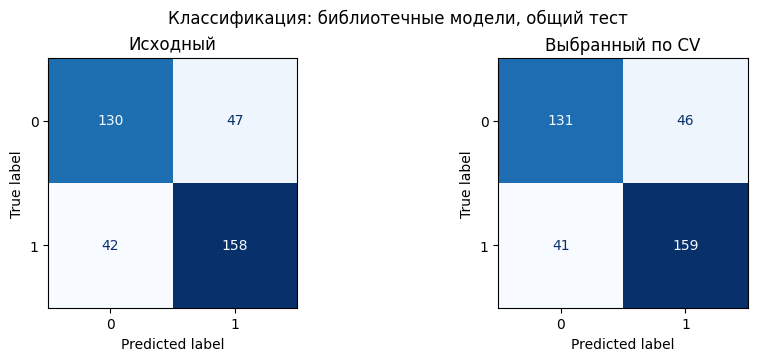

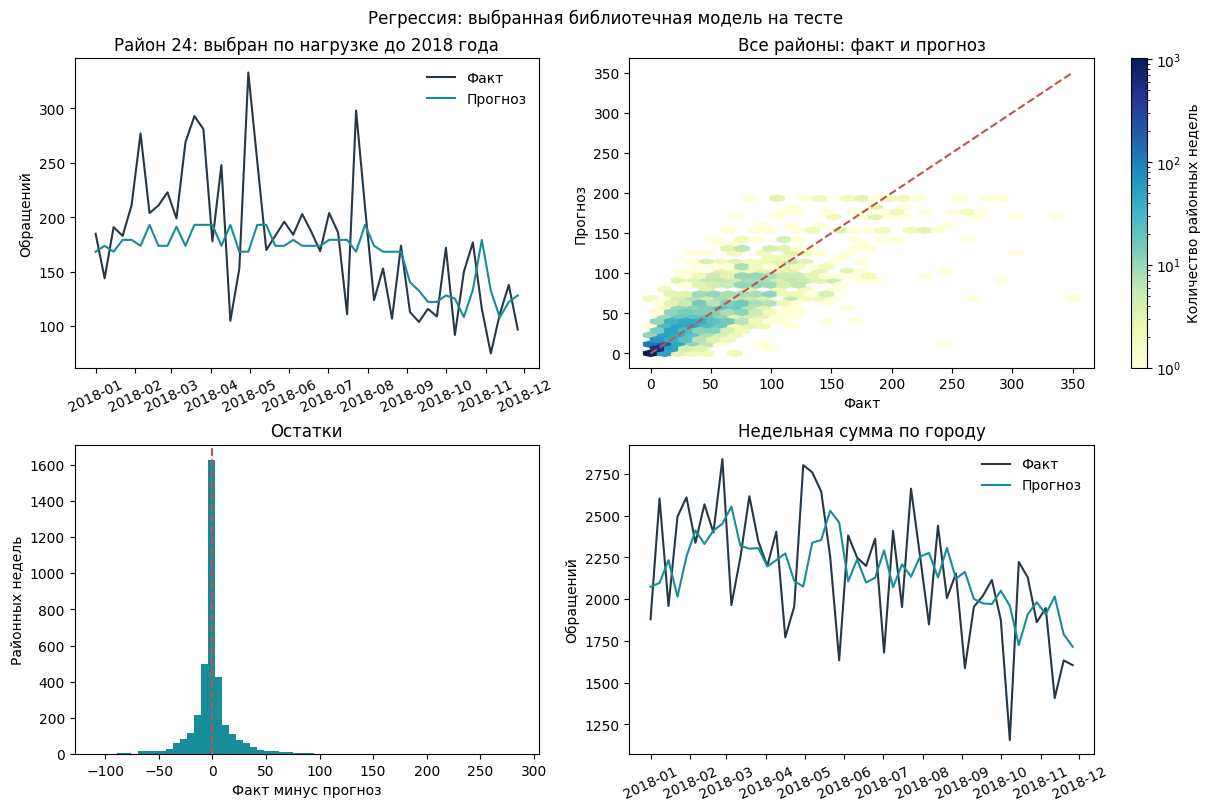

Отрицательных регрессионных прогнозов: 0


In [9]:
plot_test_errors()

Графики позволяют оценить пропуски и ложные положительные ответы классификатора, сглаживание всплесков регрессии и крупные остатки. Их используем для объяснения уже полученных оценок, без повторного подбора параметров по тесту.

## 6. Сохранение результатов

Запишем восемь тестовых оценок, таблицы CV, параметры, подготовку признаков и контрольные суммы данных и разбиений в JSON. Формат совместим с первой работой. 

In [10]:
payload = save_results()

Сохранено: results\lab03_tree.json


## 7. Выводы

В работе исследовали библиотечные модели и собственные реализации для двух задач. Все гипотезы сравнивали на общих фолдах: стратифицированных для анкет и временных для обращений. Предобработка обучалась внутри фолда. Итоговые оценки рассчитали на тех же отложенных данных, что в остальных работах.

В классификации по CV выбрали «Большая глубина» со средней F1 0.7922. На тесте библиотечная модель получила 0.7852 против 0.7802 у исходной, собственная — 0.7833. Качество библиотечной модели на тесте улучшилось; совпадение направления изменений на CV и тесте не гарантируется.

В регрессии по CV выбрали «Крупнее листья» со средней MAE 11.0932. На тесте библиотечная модель получила 11.0892 против 11.0660 у исходной, собственная — 11.0499. Качество библиотечной модели на тесте ухудшилось; совпадение направления изменений на CV и тесте не гарантируется.

Собственные деревья рассматривают ограниченный набор порогов. Это делает вычисления доступными на CPU, но влияет на разбиения и качество относительно sklearn. Сравнение показывает результат именно этих реализаций при одинаковых внешних условиях.

Результаты ограничены выбранными данными и периодами. Крупные остатки регрессии нужно учитывать вместе со средней ошибкой, а классификационные метрики — вместе с матрицами ошибок. Восемь тестовых оценок, значения CV и описание условий сохранены в JSON для итогового сравнения.